# HL60 single-shot holographic wavefield


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`hologram`，shape `(1, 200, 210)`，dtype `|u1`：Original deposited cell interference intensity inADU；`empty_hologram`，shape `(1, 200, 210)`，dtype `|u1`：Independent empty-field interference intensity inADU。未知量为HL60细胞200×210复相对透射波场。

获取模型：物光与离轴参考波叠加取模平方形成物体/独立空场全息图。

如何恢复：src.solvers.reconstruct；physics_model.recover_field傅里叶侧带分离，空场复比值；visualization.run_experiments执行恢复。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell6三图含原始/空场、傅里叶侧带与复振幅/相位和孔径实验；cell9显式冻结指标。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。没有独立细胞厚度/折射率真值，空场只是校准。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct the relative complex optical wavefield of a real HL60 cell from a single spatial-carrier hologram despite overlapping diffraction orders and reference aberrations.

The microscope records a spatial-carrier interference pattern from an actual HL60 myeloid leukemia cell, with a separately measured empty reference. The complete200×210detector region is retained. This notebook actively computes the full relative complex transmission and actual aperture-sensitivity experiments; archived original measurements are used only for comparison.


## 2. Data

| Key | Shape | Dtype | Description |
|---|---|---|---|
| hologram | (1, 200, 210) | uint8 | Original deposited cell interference intensity inADU |
| empty_hologram | (1, 200, 210) | uint8 | Independent empty-field interference intensity inADU |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Specimen | HL60 myeloid leukemia cell | identifier | Actual measured single-cell specimen |
| Exposure count | one cell and one empty | exposure | Spatial rather than temporal phase multiplexing |
| Native region | 200 rows ×210 columns | pixel | Complete deposited region, no ROI selection |
| Detector encoding | unsigned 8-bit | ADU | Original deposited digital precision |
| Coordinates | x increases right, y increases down | pixel | Camera-plane orientation retained |
| Spatial carrier | determined from observed upper sideband | cycles/pixel | Same carrier used for independent reference |
| Reference observation | separate empty field | ADU | Independent optical baseline, not a clean cell answer |
| Boundaries | finite observation, top-left zero extension | dimensionless | Native pixels are not reflected or spatially wrapped |
| Physical pitch/wavelength | not deposited with this example | unavailable | Report native detector pixels and relative optical wavefield |
| Noise variance | not independently calibrated | unavailable | No invented variance or absolute power calibration |


## 3. Physics

The measurement is a complete200×210 pixel hologram of an HL60 myeloid leukemia cell and a separately recorded empty-field hologram with the same optical configuration. For camera coordinatesr=(y,x), the model is


$$
I(r)=|O(r)+R(r)|^2+\eta(r),\qquad
R(r)=A(r)e^{-2\pi i f\cdot r},\qquad
I_b(r)=|O_b(r)+R_b(r)|^2+\eta_b(r).
$$


I andI_b are measured object and empty intensities inADU; O and O_b are transmitted optical waves, R andR_breference waves, A is reference amplitude, f spatial carrier incycles/pixel, i the imaginary unit, eta and eta_bnoise/model errors. O,R have amplitude units sqrt(ADU) under this digital intensity convention. Subscript b denotes an independent empty observation. The two displaced cross-term sidebands encode complex quadratures; separating one sideband is imperfect because the central and sideband spectral supports partly overlap. Recover the full bandlimited relative complex transmission, using the same sideband/aperture for object and empty fields. Absolute cell thickness and refractive index are not determined by this one projection.


## 4. Method

### Wave physics and explicit inverse
Intensity is I=|O+R|², where O is the object wave and R the tilted reference. Its Fourier spectrum contains a central intensity term and two conjugate cross-term sidebands. The selected upper sideband preserves one complex quadrature pair. Mean subtraction, zero extension, a smoothed circular aperture and integer Fourier translation recover the bandlimited object-reference field. The same aperture/translation is used for the independent empty observation; their ratio is the relative complex transmission. No conversion into thickness/refractive index is made.

The three figure groups retain the upstream example scientific comparisons: object/background observations, original/filtered Fourier spectra, retrieved phase, and continuous phase. Full relative amplitude and five actually reconstructed aperture conditions extend those comparisons. The review-only sequential local phase-unwrapping formula is independently verified to agree with the original example reliability unwrap on this bound smooth sample. It is not used by the solver output or Judge.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,make_figures
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
start=time.perf_counter()
experiments=run_experiments(data,upstream)
print(json.dumps({'fresh_runtime_s':time.perf_counter()-start,**experiments['metrics']},indent=2))

{
  "fresh_runtime_s": 0.3644226000033086,
  "upstream_relative_l2": 0.0,
  "minimum_empty_field_amplitude": 2.679112244654043,
  "phase_range_rad": [
    -0.5167363453538248,
    5.099589460934455
  ]
}


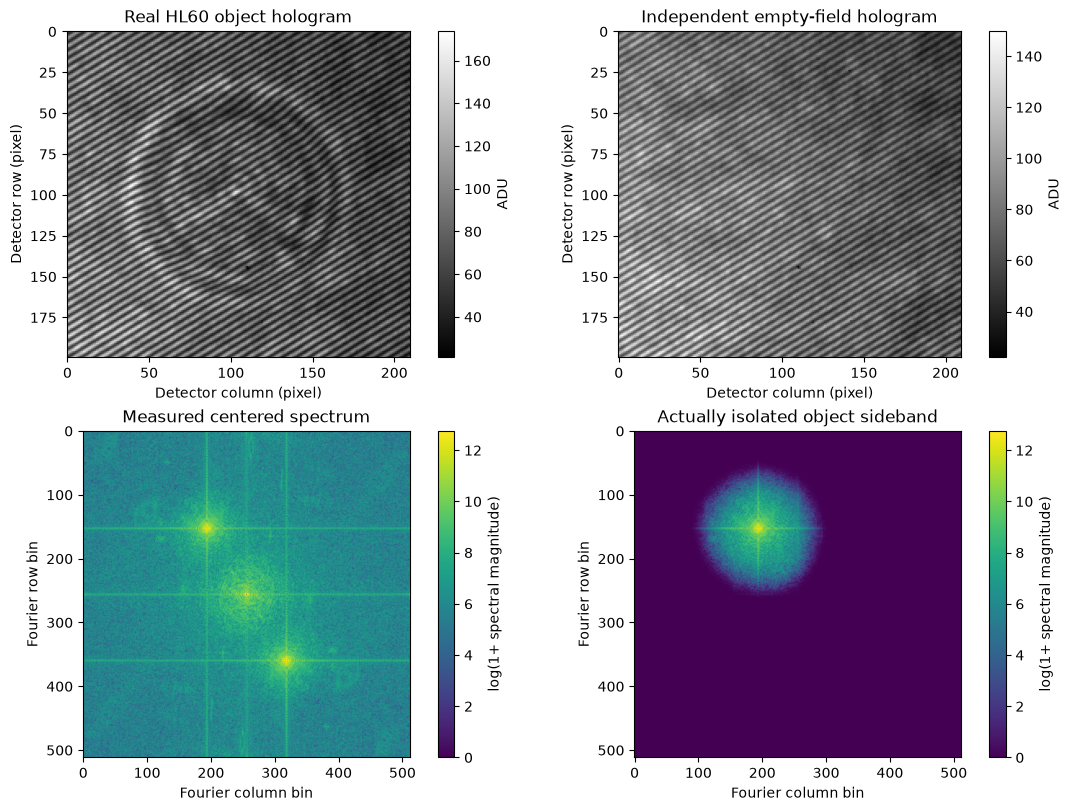

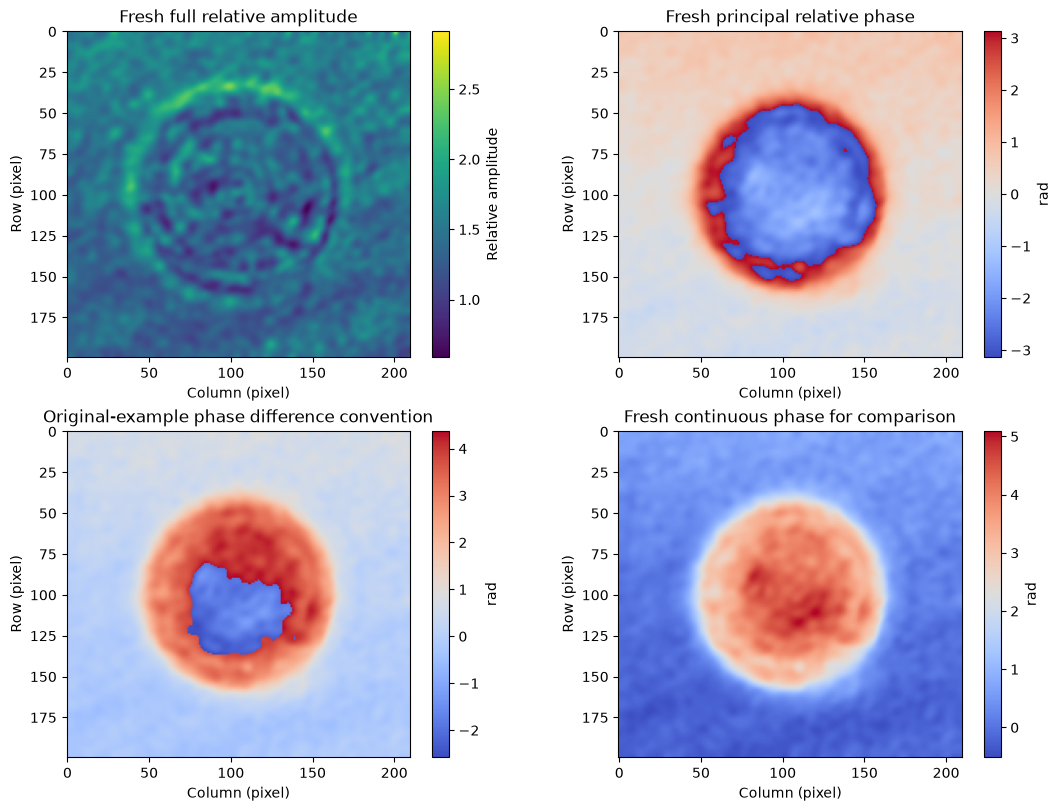

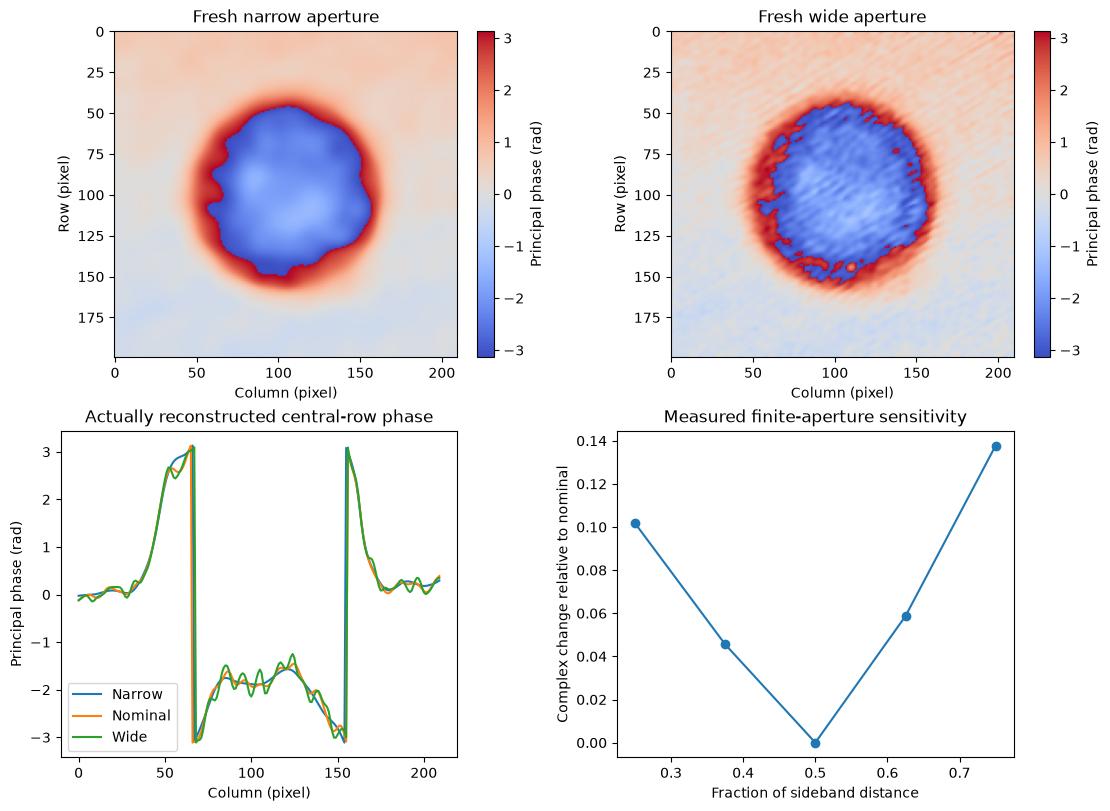

In [2]:
figures=make_figures(data,experiments)
for fig in figures:
    display(fig)
    plt.close(fig)

### Interpretation

The complex image agrees with independent execution of the original author implementation. The finite aperture has limited effective resolution because the sidebands partly overlap; the original author explicitly identifies this limitation for the sample. The independent reference fixes the digital phase/amplitude origin. Large changes under aperture width illustrate finite-bandwidth sensitivity rather than an independent biological accuracy result. All figures use fresh computation.


The following separately identified cleaned-run measurements are frozen scalar results from this task’s fresh local experiment run. The active reconstruction above remains the source of every plotted result; this archive records numeric provenance rather than supplying a reconstruction.


In [3]:
with np.load(root / 'notebooks/reference_outputs/cleaned_metrics.npz', allow_pickle=False) as recorded:
    print('Separately archived fresh cleaned-run measurements:', {k: recorded[k].tolist() for k in recorded.files})


Separately archived fresh cleaned-run measurements: {'upstream_relative_l2': 0.0, 'minimum_empty_field_amplitude': 2.679112244654043, 'phase_range_rad': [-0.5167363453538248, 5.099589460934455]}


## 6. Conclusion

The empty hologram fixes relative complex transmission, with the selected sideband fixing conjugacy. Aperture changes test bandwidth sensitivity and sideband overlap. Continuous phase is a review diagnostic and does not independently determine cell thickness or refractive index.
